In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

# Change this one path when the project is moved.
PROJECT_DIR = Path.cwd()

OUTPUT = PROJECT_DIR / "prepared_data"
splits = np.load(OUTPUT / "tabular_splits.npz")

X_train = splits["X_train"]
X_validation = splits["X_validation"]
X_test = splits["X_test"]
y_train = splits["y_train"]
y_validation = splits["y_validation"]
y_test = splits["y_test"]

print(f"Train: {X_train.shape}, validation: {X_validation.shape}, test: {X_test.shape}")
print("Target distribution:")
print(pd.Series(y_train).value_counts().sort_index())


Train: (16479, 286), validation: (3531, 286), test: (3532, 286)
Target distribution:
0     3877
1    12602
Name: count, dtype: int64


Prediction

In [4]:
# Random Forest trained on the shared chronological preprocessing output.
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

model_rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1)
model_rf.fit(X_train, y_train)

prediksi_validation = model_rf.predict(X_validation)
prediksi_rf = model_rf.predict(X_test)
probabilitas_rf = model_rf.predict_proba(X_test)[:, 1]

print("Validation classification report:")
print(classification_report(y_validation, prediksi_validation, zero_division=0))
print(f"Validation ROC-AUC: {roc_auc_score(y_validation, model_rf.predict_proba(X_validation)[:, 1]):.4f}")

akurasi_rf = accuracy_score(y_test, prediksi_rf)
print(f"Test accuracy: {akurasi_rf:.4f}")
print("\nTest classification report:")
print(classification_report(y_test, prediksi_rf, zero_division=0))
print(f"Test ROC-AUC: {roc_auc_score(y_test, probabilitas_rf):.4f}")

matriks_kebingungan_rf = pd.DataFrame(
    confusion_matrix(y_test, prediksi_rf, labels=model_rf.classes_),
    index=[f"Actual {kelas}" for kelas in model_rf.classes_],
    columns=[f"Predicted {kelas}" for kelas in model_rf.classes_],
)
print("\nConfusion matrix:")
print(matriks_kebingungan_rf)


Validation classification report:
              precision    recall  f1-score   support

           0       0.60      0.52      0.56       883
           1       0.85      0.89      0.87      2648

    accuracy                           0.79      3531
   macro avg       0.73      0.70      0.71      3531
weighted avg       0.79      0.79      0.79      3531

Validation ROC-AUC: 0.8378
Test accuracy: 0.7653

Test classification report:
              precision    recall  f1-score   support

           0       0.59      0.57      0.58       998
           1       0.83      0.84      0.84      2534

    accuracy                           0.77      3532
   macro avg       0.71      0.70      0.71      3532
weighted avg       0.76      0.77      0.76      3532

Test ROC-AUC: 0.8158

Confusion matrix:
          Predicted 0  Predicted 1
Actual 0          564          434
Actual 1          395         2139


Matplotlib is building the font cache; this may take a moment.


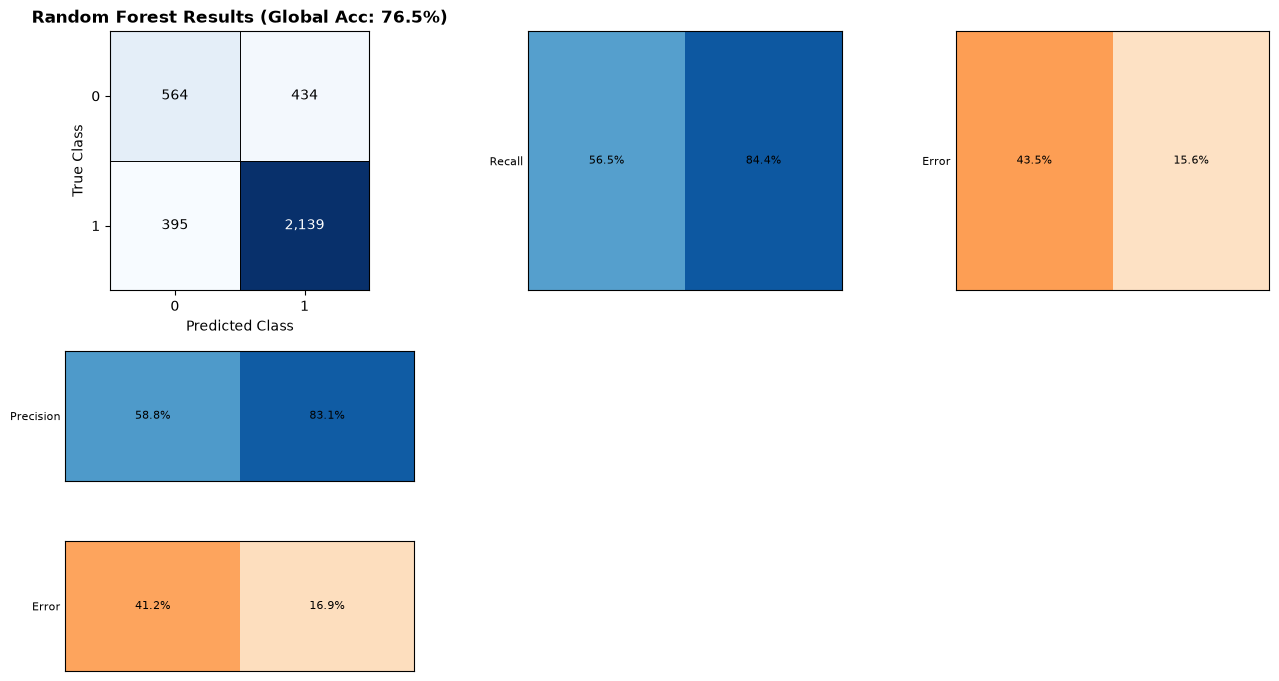

In [3]:
# Plot confusion matrix with prediction classes and percentages
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix

kelas = model_rf.classes_
cm = confusion_matrix(y_test, prediksi_rf, labels=kelas)
total = cm.sum()
row_totals = cm.sum(axis=1)
column_totals = cm.sum(axis=0)
recall = np.divide(np.diag(cm), row_totals, out=np.zeros_like(row_totals, dtype=float), where=row_totals != 0) * 100
precision = np.divide(np.diag(cm), column_totals, out=np.zeros_like(column_totals, dtype=float), where=column_totals != 0) * 100
row_error = 100 - recall
column_error = 100 - precision

fig = plt.figure(figsize=(max(14, len(kelas) * 1.5), 8))
grid = fig.add_gridspec(
    nrows=3,
    ncols=3,
    width_ratios=[len(kelas), 1.8, 1.8],
    height_ratios=[len(kelas), 1, 1],
    wspace=0.35,
    hspace=0.35,
)

ax = fig.add_subplot(grid[0, 0])
image = ax.imshow(cm, cmap="Blues")
threshold = cm.max() / 2
for i in range(len(kelas)):
    for j in range(len(kelas)):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                color="white" if cm[i, j] > threshold else "black")
ax.set_xticks(range(len(kelas)), labels=kelas)
ax.set_yticks(range(len(kelas)), labels=kelas)
ax.set_xlabel("Predicted Class")
ax.set_ylabel("True Class")
ax.set_title(f"Random Forest Results (Global Acc: {akurasi_rf:.1%})", fontweight="bold")
ax.set_xticks(np.arange(-.5, len(kelas), 1), minor=True)
ax.set_yticks(np.arange(-.5, len(kelas), 1), minor=True)
ax.grid(which="minor", color="black", linestyle="-", linewidth=0.7)
ax.tick_params(which="minor", bottom=False, left=False)

def add_percentage_panel(panel, values, title, color):
    panel.imshow(np.asarray(values).reshape(1, -1), cmap=color, vmin=0, vmax=100, aspect="auto")
    for index, value in enumerate(values):
        panel.text(index, 0, f"{value:.1f}%", ha="center", va="center", fontsize=8)
    panel.set_xticks([])
    panel.set_yticks([0], labels=[title], fontsize=8)
    panel.tick_params(length=0)

ax_recall = fig.add_subplot(grid[0, 1])
add_percentage_panel(ax_recall, recall, "Recall", "Blues")
ax_error = fig.add_subplot(grid[0, 2])
add_percentage_panel(ax_error, row_error, "Error", "Oranges")

ax_precision = fig.add_subplot(grid[1, 0])
add_percentage_panel(ax_precision, precision, "Precision", "Blues")
ax_column_error = fig.add_subplot(grid[2, 0])
add_percentage_panel(ax_column_error, column_error, "Error", "Oranges")
fig.subplots_adjust(left=0.10, right=0.96, bottom=0.10, top=0.90)
plt.show()
